In [8]:
%pip install tensorflow numpy pandas matplotlib seaborn scikit-learn pillow streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [78]:
# ==========================================
# IMPORT LIBRARY
# KLASIFIKASI IMAGE OCEANICLIFE MENGGUNAKAN CNN
# ==========================================

# Library dasar
import os
import json
import time
import math
import random

# Pengolahan data
import numpy as np
import pandas as pd

# Visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Pengolahan gambar
from PIL import Image

# Deep Learning
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam

# Callback training
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# Evaluasi model
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# ==========================================
# CEK VERSI DAN PERANGKAT
# ==========================================

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

print("\nSemua library berhasil di-import!")

TensorFlow Version: 2.22.0-rc0
NumPy Version: 2.5.3
Pandas Version: 3.0.6
GPU Available: []

Semua library berhasil di-import!


In [79]:
# ==========================================
# KONFIGURASI PERANGKAT
# ==========================================

# Menggunakan CPU
tf.config.set_visible_devices([], 'GPU')

print("Perangkat yang digunakan: CPU")
print("CPU Available:", tf.config.list_physical_devices('CPU'))

Perangkat yang digunakan: CPU
CPU Available: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [80]:
# ==========================================
# KONFIGURASI DATASET OCEANICLIFE
# ==========================================

BASE_DIR = r"C:\Users\Hype AMD\Documents\Klasifikasi_Image_Menggunakan_CNN\OceanicLife Dataset"

IMG_SIZE = (160, 160)      # bobot ImageNet MobileNetV2 tersedia untuk 96/128/160/192/224
BATCH_SIZE = 32

EPOCHS = 15                # fase 1: latih "kepala" klasifikasi
FINE_TUNE_EPOCHS = 5       # fase 2: fine-tune sebentar

SEED = 42
WEIGHTS = "imagenet"       # isi None jika tidak bisa mengunduh bobot (akurasi akan lebih rendah)

OUT_DIR = "output_oceaniclife"

os.makedirs(OUT_DIR, exist_ok=True)

tf.keras.utils.set_random_seed(SEED)

analysis = {}   # teks analisis otomatis -> dibaca dashboard Streamlit

if not os.path.exists(BASE_DIR):
    raise FileNotFoundError(
        f"Folder dataset tidak ditemukan: {BASE_DIR}"
    )

print("Dataset ditemukan:", BASE_DIR)

# Mengambil semua file gambar (termasuk sub-folder, folder output diabaikan)
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".gif")
out_abs = os.path.abspath(OUT_DIR)

image_paths = []
for root, _, files in os.walk(BASE_DIR):
    if os.path.abspath(root).startswith(out_abs):
        continue
    for f in files:
        if f.lower().endswith(image_extensions):
            image_paths.append(os.path.join(root, f))
image_paths = sorted(image_paths)

print("Total gambar:", len(image_paths))
if not image_paths:
    raise RuntimeError("Tidak ada gambar (jpg/jpeg/png/bmp/gif) di BASE_DIR. Periksa path dataset.")

Dataset ditemukan: C:\Users\Hype AMD\Documents\Klasifikasi_Image_Menggunakan_CNN\OceanicLife Dataset
Total gambar: 2007


In [81]:
# ==========================================
# MENENTUKAN KELAS DATASET
# ==========================================

class_names = [
    "Fish",
    "Coral",
    "Shark",
    "Octopuses",
    "Crustaceans",
    "Seaweed",
    "Sponges",
    "Other marine organisms"
]

class_to_index = {name: index for index, name in enumerate(class_names)}
index_to_class = {index: name for name, index in class_to_index.items()}

NUM_CLASSES = len(class_names)

print("Jumlah kelas:", NUM_CLASSES)

print("\nDaftar kelas:")
for name, index in class_to_index.items():
    print(f"{index} = {name}")

with open(os.path.join(OUT_DIR, "class_names.json"), "w") as f:
    json.dump(class_names, f)

Jumlah kelas: 8

Daftar kelas:
0 = Fish
1 = Coral
2 = Shark
3 = Octopuses
4 = Crustaceans
5 = Seaweed
6 = Sponges
7 = Other marine organisms


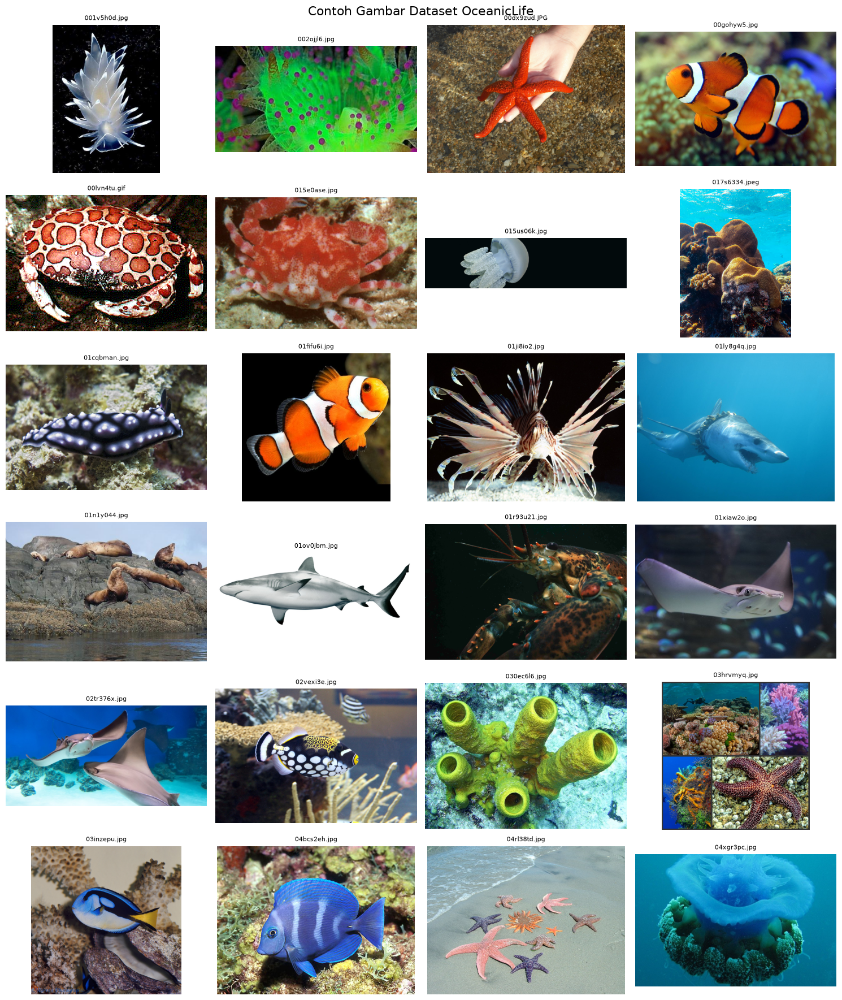

In [82]:
# ==========================================
# MENAMPILKAN CONTOH DATASET
# ==========================================

sample_paths = image_paths[:24]

rows = math.ceil(len(sample_paths) / 4)

plt.figure(figsize=(15, rows * 3))

for i, path in enumerate(sample_paths):

    try:
        img = Image.open(path).convert("RGB")

        plt.subplot(rows, 4, i + 1)
        plt.imshow(img)
        plt.title(os.path.basename(path), fontsize=8)
        plt.axis("off")

    except Exception as e:
        print("Gagal membaca:", path)

plt.suptitle("Contoh Gambar Dataset OceanicLife", fontsize=16)

plt.tight_layout()
plt.show()

In [83]:
# ==========================================
# PELABELAN GAMBAR SECARA MANUAL
# ==========================================

LABEL_MODE = "batch"       # "batch" = 12 gambar per input | "single" = satu per satu
GRID = 12

try:
    from IPython.display import clear_output
except ImportError:
    clear_output = lambda *a, **k: None

label_file = os.path.join(OUT_DIR, "oceaniclife_labels.csv")


def rel_name(path):
    try:
        return os.path.relpath(path, BASE_DIR)
    except ValueError:
        return os.path.basename(path)


# Jika CSV sudah pernah dibuat, lanjutkan gambar yang belum diberi label.
if os.path.exists(label_file):
    labels_df = pd.read_csv(label_file)
    if "filename" not in labels_df.columns:
        labels_df["filename"] = labels_df["filepath"].apply(rel_name)
else:
    labels_df = pd.DataFrame(columns=["filepath", "filename", "label", "label_id"])

labeled_files = set(labels_df["filename"].tolist())
todo = [p for p in image_paths if rel_name(p) not in labeled_files]

print("DAFTAR KELAS:")
for index, name in enumerate(class_names):
    print(f"{index} = {name}")

print(f"\nSudah dilabeli : {len(labeled_files)}")
print(f"Belum dilabeli : {len(todo)}\n")

new_rows = []


def add_row(path, label_id):
    if label_id < 0:
        name = "skip"
    else:
        name = index_to_class[label_id]
    new_rows.append({
        "filepath": path, "filename": rel_name(path),
        "label": name, "label_id": label_id
    })


def save_labels():
    global labels_df, new_rows
    if new_rows:
        labels_df = pd.concat([labels_df, pd.DataFrame(new_rows)], ignore_index=True)
        new_rows = []
    labels_df.to_csv(label_file, index=False)


valid_chars = "-" + "".join(str(i) for i in range(NUM_CLASSES))
stop = False

if LABEL_MODE == "batch":

    for start in range(0, len(todo), GRID):
        batch_paths = todo[start:start + GRID]
        n = len(batch_paths)
        cols = 4
        nrows = math.ceil(n / cols)

        clear_output(wait=True)
        plt.figure(figsize=(14, nrows * 3.6))
        for i, path in enumerate(batch_paths):
            try:
                img = Image.open(path).convert("RGB")
            except Exception:
                img = Image.new("RGB", (64, 64), "black")
            plt.subplot(nrows, cols, i + 1)
            plt.imshow(img)
            plt.title(f"[{i + 1}]", fontsize=16, fontweight="bold")
            plt.axis("off")
        plt.tight_layout()
        plt.show()

        print("Kelas: " + " | ".join(f"{i}={nm}" for i, nm in enumerate(class_names)))
        print(f"Gambar {start + 1}-{start + n} dari {len(todo)} yang belum dilabeli")

        while True:
            ans = input(
    f"Masukkan {n} label sekaligus (0-{NUM_CLASSES - 1}, '-' untuk skip, q untuk berhenti): "
            ).strip().lower()
            if ans == "q":
                stop = True
                break
            code_str = ans.replace(" ", "").replace(",", "")
            if len(code_str) == n and all(ch in valid_chars for ch in code_str):
                break
            print(f"Input tidak valid: butuh tepat {n} karakter (angka 0-{NUM_CLASSES - 1} atau '-').")

        if stop:
            break

        for path, ch in zip(batch_paths, code_str):
            add_row(path, -1 if ch == "-" else int(ch))
        save_labels()

else:

    for path in todo:

        try:
            img = Image.open(path).convert("RGB")

            clear_output(wait=True)
            plt.figure(figsize=(5, 5))
            plt.imshow(img)
            plt.title(os.path.basename(path))
            plt.axis("off")
            plt.show()

            print("Nama gambar:", os.path.basename(path))

            label_input = input(
                f"Masukkan nomor kelas (0-{NUM_CLASSES - 1}), skip, atau q untuk berhenti: "
            ).strip().lower()

            if label_input == "q":
                break

            if label_input == "skip":
                add_row(path, -1)
                save_labels()
                continue

            if not label_input.isdigit() or int(label_input) not in range(NUM_CLASSES):
                print("Input tidak valid.")
                continue

            add_row(path, int(label_input))
            save_labels()
            print("Label berhasil disimpan:", index_to_class[int(label_input)])

        except Exception as e:
            print("Gagal memproses gambar:", e)

save_labels()

clear_output(wait=True)
print("Proses pelabelan selesai / dihentikan.")
print("Gambar yang sudah dilabeli (tidak termasuk skip):", int((labels_df["label_id"] >= 0).sum()))
print("\nJumlah per kelas:")
print(labels_df[labels_df["label_id"] >= 0]["label"].value_counts().reindex(class_names).fillna(0).astype(int).to_string())

Proses pelabelan selesai / dihentikan.
Gambar yang sudah dilabeli (tidak termasuk skip): 127

Jumlah per kelas:
label
Fish                      18
Coral                     14
Shark                     15
Octopuses                 18
Crustaceans               22
Seaweed                   15
Sponges                   10
Other marine organisms    15


In [85]:
# Membaca label sebelumnya
if os.path.exists(label_file):
    labels_df = pd.read_csv(label_file)
else:
    labels_df = pd.DataFrame(columns=["filename", "label_id"])

# Mengambil gambar yang sudah dilabeli
sudah_dilabeli = set(
    labels_df.loc[
        labels_df["label_id"] >= 0,
        "filename"
    ]
)

# Mengambil gambar yang belum dilabeli
belum_dilabeli = [
    p for p in image_paths
    if os.path.basename(p) not in sudah_dilabeli
]

print("Sudah dilabeli:", len(sudah_dilabeli))
print("Belum dilabeli:", len(belum_dilabeli))

Sudah dilabeli: 127
Belum dilabeli: 1880


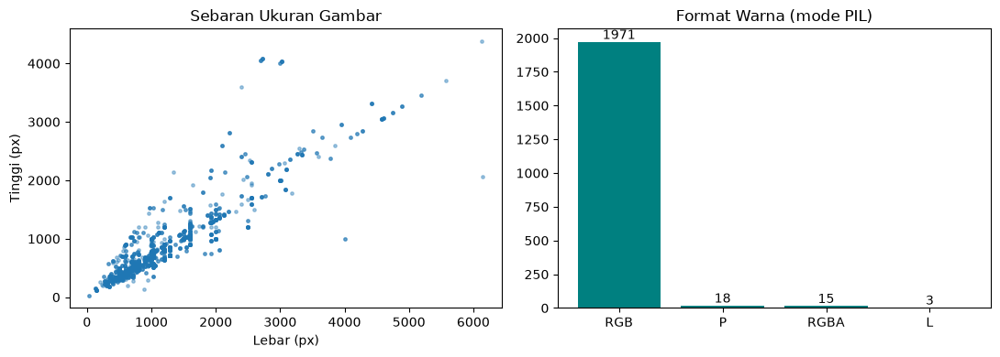

Analisis: Dari 2007 file, lebar rata-rata 1183px (min 32, maks 6144); tinggi rata-rata 863px (min 32, maks 4378). Mode warna: {'RGB': 1971, 'P': 18, 'RGBA': 15, 'L': 3}. File rusak: 0. Karena ukuran tidak seragam dan mode warna bisa bercampur (grayscale/RGBA/palette), semua gambar di-resize ke 160x160 dan dibaca sebagai RGB.


In [86]:
# ---- (a) ukuran gambar, format warna, kualitas (file rusak) -> seluruh dataset
widths, heights, modes, bad = [], [], [], []
for p in image_paths:
    try:
        with Image.open(p) as im:
            w_, h_, m_ = im.size[0], im.size[1], im.mode
            im.verify()
        widths.append(w_); heights.append(h_); modes.append(m_)
    except Exception:
        bad.append(p)

widths, heights = np.array(widths), np.array(heights)
mode_counts = pd.Series(modes).value_counts()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(widths, heights, s=6, alpha=0.4)
axes[0].set_title("Sebaran Ukuran Gambar"); axes[0].set_xlabel("Lebar (px)"); axes[0].set_ylabel("Tinggi (px)")
b = axes[1].bar(mode_counts.index.astype(str), mode_counts.values, color="teal")
axes[1].bar_label(b)
axes[1].set_title("Format Warna (mode PIL)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "3_image_properties.png"), dpi=120)
plt.show()

if bad:
    print(f"PERINGATAN: {len(bad)} file rusak (otomatis dikeluarkan dari training):")
    print("\n".join(bad[:20]))

analysis["eda_ukuran"] = (
    f"Dari {len(image_paths)} file, lebar rata-rata {widths.mean():.0f}px (min {widths.min()}, maks {widths.max()}); "
    f"tinggi rata-rata {heights.mean():.0f}px (min {heights.min()}, maks {heights.max()}). "
    f"Mode warna: {mode_counts.to_dict()}. File rusak: {len(bad)}. Karena ukuran tidak seragam dan mode warna bisa "
    f"bercampur (grayscale/RGBA/palette), semua gambar di-resize ke {IMG_SIZE[0]}x{IMG_SIZE[1]} dan dibaca sebagai RGB."
)
print("Analisis:", analysis["eda_ukuran"])

In [87]:
# ==========================================
# MEMBACA LABEL DAN MEMERIKSA JUMLAH DATA
# ==========================================

labels_df = pd.read_csv(label_file)

# Ambil hanya gambar yang sudah memiliki label valid
df = labels_df[labels_df["label_id"] >= 0].copy()

# Membuat lokasi file gambar
df["path"] = df["filename"].apply(
    lambda f: os.path.join(BASE_DIR, f)
)

# Memastikan file gambar benar-benar tersedia
df = df[df["path"].apply(os.path.exists)].copy()

df["label_id"] = df["label_id"].astype(int)
df["label"] = df["label_id"].map(index_to_class)

# Hapus label yang tidak termasuk delapan kelas
df = df[df["label"].isin(class_names)].copy()

# Tampilkan jumlah data setiap kelas
counts = (
    df["label"]
    .value_counts()
    .reindex(class_names)
    .fillna(0)
    .astype(int)
)

print("TOTAL GAMBAR BERLABEL:", len(df))
print("\nJUMLAH GAMBAR PER KELAS:")
print(counts)

# Periksa apakah semua kelas sudah memiliki data
kelas_kosong = counts[counts == 0]

if len(kelas_kosong) > 0:
    print("\nPERINGATAN! Kelas berikut belum memiliki gambar:")
    print(kelas_kosong)

# Periksa jumlah minimal untuk pembagian data
kelas_kurang = counts[counts < 3]

if len(kelas_kurang) > 0:
    print("\nPERINGATAN! Kelas berikut memiliki kurang dari 3 gambar:")
    print(kelas_kurang)
    raise ValueError(
        "Tambahkan dan periksa label gambar terlebih dahulu. "
        "Setiap kelas minimal harus memiliki 3 gambar untuk split 70:15:15."
    )

print("\nSemua kelas sudah memiliki data dan dapat dibagi.")

TOTAL GAMBAR BERLABEL: 127

JUMLAH GAMBAR PER KELAS:
label
Fish                      18
Coral                     14
Shark                     15
Octopuses                 18
Crustaceans               22
Seaweed                   15
Sponges                   10
Other marine organisms    15
Name: count, dtype: int64

Semua kelas sudah memiliki data dan dapat dibagi.


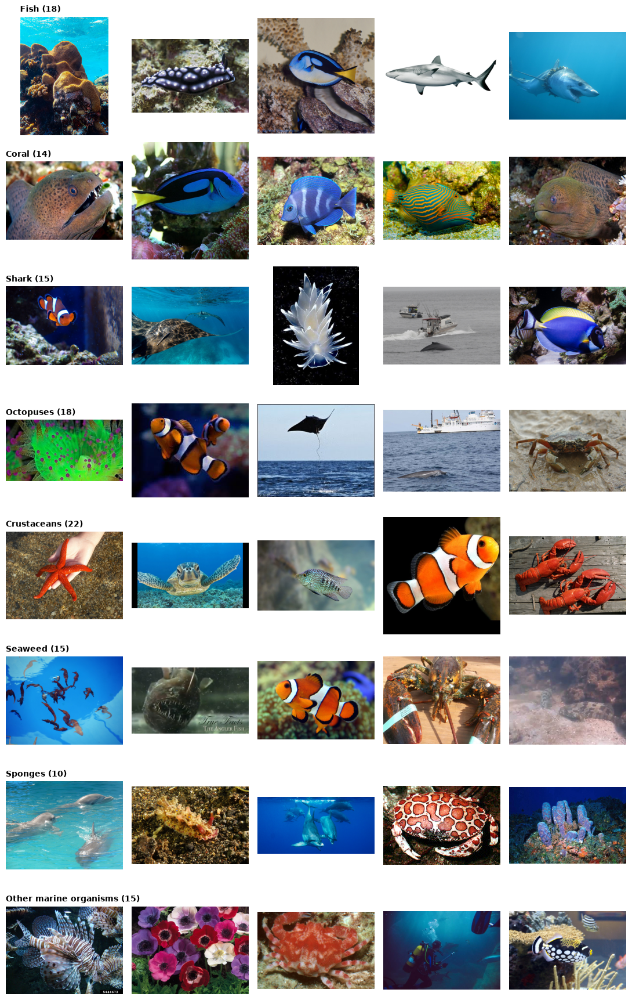

Analisis: Contoh visual tiap kelas menunjukkan variasi sudut pandang, pencahayaan (air laut cenderung kebiruan/kehijauan), latar belakang, dan ukuran objek. Kelas dengan bentuk mirip (mis. Fish vs Shark, Coral vs Sponges) berpotensi saling tertukar, sehingga augmentasi data dipakai untuk menambah variasi. Angka dalam kurung adalah jumlah gambar berlabel.


In [88]:
# ---- (c) contoh gambar tiap kelas
N_EX = 5
fig, axes = plt.subplots(NUM_CLASSES, N_EX, figsize=(2.2 * N_EX, 2.2 * NUM_CLASSES))
for r, c in enumerate(class_names):
    sub = df[df.label == c]
    pick = sub.sample(min(N_EX, len(sub)), random_state=SEED)["path"].tolist() if len(sub) else []
    for k in range(N_EX):
        ax = axes[r, k]
        ax.axis("off")
        if k < len(pick):
            try:
                ax.imshow(Image.open(pick[k]).convert("RGB"))
            except Exception:
                pass
        if k == 0:
            ax.set_title(f"{c} ({len(sub)})", fontsize=10, loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "2_class_examples.png"), dpi=110)
plt.show()

analysis["eda_contoh"] = (
    "Contoh visual tiap kelas menunjukkan variasi sudut pandang, pencahayaan (air laut cenderung kebiruan/kehijauan), "
    "latar belakang, dan ukuran objek. Kelas dengan bentuk mirip (mis. Fish vs Shark, Coral vs Sponges) berpotensi "
    "saling tertukar, sehingga augmentasi data dipakai untuk menambah variasi. Angka dalam kurung adalah jumlah gambar berlabel."
)
print("Analisis:", analysis["eda_contoh"])

In [89]:
# ==========================================
# PEMBAGIAN DATA TRAINING, VALIDATION, TESTING
# ==========================================

# Membagi data menjadi 70% training dan 30% sementara
tr_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label_id"],
    random_state=SEED
)

# Membagi data sementara menjadi validation dan testing
va_df, te_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label_id"],
    random_state=SEED
)

print("Data Training   :", len(tr_df))
print("Data Validation :", len(va_df))
print("Data Testing    :", len(te_df))


# ==========================================
# PREPROCESSING GAMBAR
# ==========================================

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(
        img, channels=3, expand_animations=False
    )
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(tf.round(img), tf.uint8)
    img.set_shape(IMG_SIZE + (3,))
    return img, tf.one_hot(label, NUM_CLASSES)


def to_float(x, y):
    return tf.cast(x, tf.float32), y


AUTOTUNE = tf.data.AUTOTUNE

# Dataset training
train_ds = (
    tf.data.Dataset.from_tensor_slices(
        (tr_df["path"].values, tr_df["label_id"].values)
    )
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .cache()
    .shuffle(1000, seed=SEED)
    .batch(BATCH_SIZE)
    .map(to_float, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

# Dataset validation
val_ds = (
    tf.data.Dataset.from_tensor_slices(
        (va_df["path"].values, va_df["label_id"].values)
    )
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .cache()
    .batch(BATCH_SIZE)
    .map(to_float, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

# Dataset testing
test_ds = (
    tf.data.Dataset.from_tensor_slices(
        (te_df["path"].values, te_df["label_id"].values)
    )
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .cache()
    .batch(BATCH_SIZE)
    .map(to_float, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)


# ==========================================
# CLASS WEIGHT
# ==========================================

tr_counts = tr_df["label_id"].value_counts()
n_present = len(tr_counts)

class_weight = {
    i: float(len(tr_df) / (n_present * tr_counts[i]))
    if i in tr_counts.index else 1.0
    for i in range(NUM_CLASSES)
}

print("\nClass Weight:")
print(class_weight)

print("\nPreprocessing berhasil!")

Data Training   : 88
Data Validation : 19
Data Testing    : 20

Class Weight:
{0: 0.8461538461538461, 1: 1.1, 2: 1.1, 3: 0.8461538461538461, 4: 0.7333333333333333, 5: 1.1, 6: 1.5714285714285714, 7: 1.1}

Preprocessing berhasil!


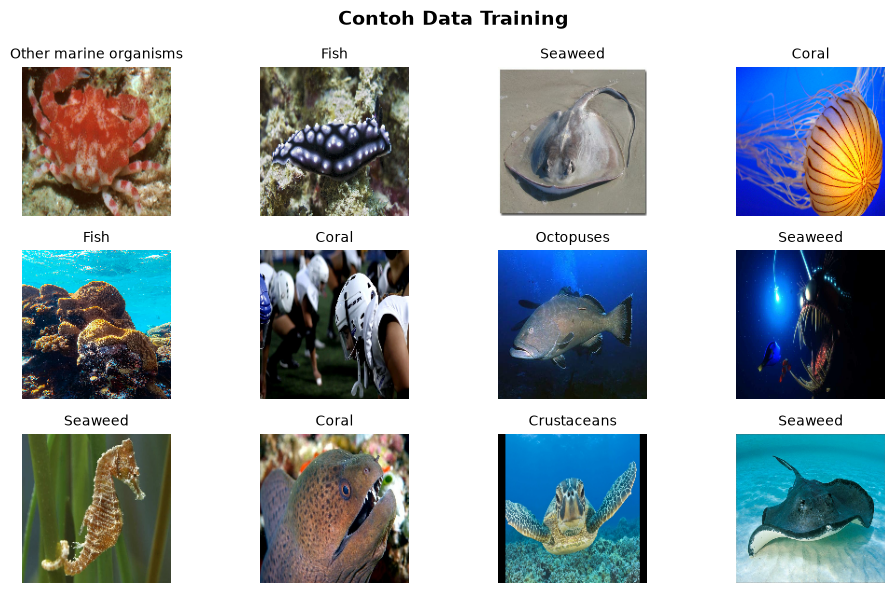

In [90]:
plt.figure(figsize=(10, 6))

for images, labels in train_ds.take(1):
    for i in range(min(12, len(images))):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(np.argmax(labels[i]))], fontsize=10)
        plt.axis("off")

plt.suptitle("Contoh Data Training", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "4_sample_data.png"), dpi=120)
plt.show()

In [91]:
import ssl
try:
    import certifi
    os.environ["SSL_CERT_FILE"] = certifi.where()
    os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()
    ssl._create_default_https_context = lambda *a, **k: ssl.create_default_context(
        cafile=certifi.where()
    )
except ImportError:
    pass

augment = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1),
], name="augmentation")

# ---- Base model pretrained ----
try:
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=IMG_SIZE + (3,),
        include_top=False,
        weights=WEIGHTS
    )
except Exception as e:
    raise RuntimeError(
        "Gagal mengunduh bobot ImageNet. Cek koneksi internet, atau set WEIGHTS = None "
        "(akurasi akan lebih rendah)."
    ) from e

base_model.trainable = False

# ----- Susun model -----
inputs = layers.Input(shape=IMG_SIZE + (3,))
x = augment(inputs)
x = layers.Rescaling(1. / 127.5, offset=-1, name="rescale")(x)   # skala [-1, 1] sesuai MobileNetV2
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name="gap")(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="head"
)(x)

model = models.Model(inputs, outputs, name="oceaniclife_mobilenetv2")
model.compile(
    optimizer=Adam(1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "oceaniclife_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head (Dense)                    │ (None, 8)              │        10,248 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,268,232 (8.65 MB)

 Trainable params: 10,248 (40.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [92]:
os.makedirs(OUT_DIR, exist_ok=True)

In [93]:
ckpt_path = os.path.join(OUT_DIR, "oceaniclife_cnn_best.keras")


def make_callbacks():
    return [
        EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True),
        ModelCheckpoint(ckpt_path, monitor="val_accuracy", save_best_only=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=1, min_lr=1e-6),
    ]


t0 = time.time()

print("\n Fase 1: latih classifier head...")
h1 = model.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds,
    class_weight=class_weight,
    callbacks=make_callbacks()
)

print("\n Fase 2: fine-tune 30 layer terakhir...")
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=Adam(1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

h2 = model.fit(
    train_ds,
    epochs=FINE_TUNE_EPOCHS,
    validation_data=val_ds,
    class_weight=class_weight,
    callbacks=make_callbacks()
)

print(f"\n Total waktu training: {(time.time() - t0) / 60:.1f} menit")

# gabungkan history kedua fase
history = {
    k: [float(v) for v in h1.history[k] + h2.history[k]]
    for k in h1.history
}
split = len(h1.history["accuracy"])


 Fase 1: latih classifier head...
Epoch 1/15


c:\Users\Hype AMD\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


3/3 ━━━━━━━━━━━━━━━━━━━━ 20s 5s/step - accuracy: 0.0795 - loss: 2.6000 - val_accuracy: 0.0526 - val_loss: 2.4699 - learning_rate: 0.0010
Epoch 2/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 666ms/step - accuracy: 0.2159 - loss: 2.1303 - val_accuracy: 0.0526 - val_loss: 2.4986 - learning_rate: 0.0010
Epoch 3/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 638ms/step - accuracy: 0.2614 - loss: 1.9972 - val_accuracy: 0.0526 - val_loss: 2.5068 - learning_rate: 3.0000e-04
Epoch 4/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 704ms/step - accuracy: 0.2614 - loss: 1.9724 - val_accuracy: 0.0526 - val_loss: 2.5055 - learning_rate: 9.0000e-05
Epoch 5/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 648ms/step - accuracy: 0.2955 - loss: 1.9536 - val_accuracy: 0.0526 - val_loss: 2.5050 - learning_rate: 2.7000e-05

 Fase 2: fine-tune 30 layer terakhir...
Epoch 1/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 20s 5s/step - accuracy: 0.1705 - loss: 2.2387 - val_accuracy: 0.0526 - val_loss: 2.4519 - learning_rate: 1.0000e-05
Epoch 2/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 779ms/step - accuracy


Akurasi Testing Akhir: 15.00%
Loss Testing: 2.4499


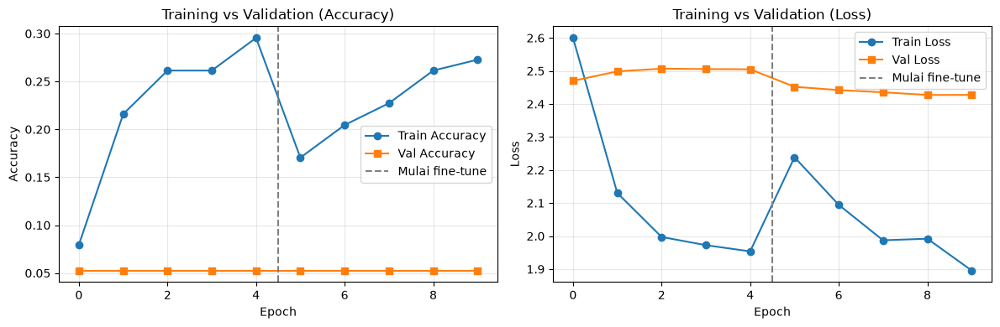


Analisis: Training berjalan 10 epoch (fase 1: 5, fase 2: 5). Akurasi akhir train 27.27% vs validasi 5.26%. Gap train-validasi besar -> indikasi overfitting. Loss yang turun lalu mendatar menandakan model sudah konvergen; garis putus-putus menandai awal fine-tuning. Akurasi train bisa tampak lebih rendah dari validasi karena augmentasi & dropout aktif saat training.


In [94]:
# 1. Evaluasi akhir menggunakan data testing
loss, acc = model.evaluate(test_ds, verbose=0)

print(f"\nAkurasi Testing Akhir: {acc * 100:.2f}%")
print(f"Loss Testing: {loss:.4f}")
# 2. Grafik akurasi dan loss
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for a, (metric, title) in zip(ax, [("accuracy", "Accuracy"), ("loss", "Loss")]):
    a.plot(history[metric], "o-", label=f"Train {title}")
    a.plot(history[f"val_{metric}"], "s-", label=f"Val {title}")

    if 0 < split < len(history[metric]):
        a.axvline(split - 0.5, color="gray", linestyle="--", label="Mulai fine-tune")

    a.set_title(f"Training vs Validation ({title})")
    a.set_xlabel("Epoch")
    a.set_ylabel(title)
    a.legend()
    a.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "5_training_curves.png"), dpi=120, bbox_inches="tight")
plt.show()

gap = history["accuracy"][-1] - history["val_accuracy"][-1]
fit_txt = ("Gap train-validasi besar -> indikasi overfitting." if gap > 0.1
           else "Gap train-validasi kecil -> model cukup generalisasi.")
analysis["kurva"] = (
    f"Training berjalan {len(history['loss'])} epoch (fase 1: {split}, fase 2: {len(history['loss']) - split}). "
    f"Akurasi akhir train {history['accuracy'][-1]:.2%} vs validasi {history['val_accuracy'][-1]:.2%}. {fit_txt} "
    "Loss yang turun lalu mendatar menandakan model sudah konvergen; garis putus-putus menandai awal fine-tuning. "
    "Akurasi train bisa tampak lebih rendah dari validasi karena augmentasi & dropout aktif saat training."
)
print("\nAnalisis:", analysis["kurva"])

In [97]:

# ==========================================
# EVALUASI MODEL DAN HASIL PREDIKSI
# ==========================================

# 1. Menghasilkan label prediksi
y_true, y_pred = [], []
imgs_keep, probs_keep = [], []

for xb, yb in test_ds:

    p = model.predict(xb, verbose=0)

    yb_np = yb.numpy()

    # Mendukung label integer dan categorical
    if len(yb_np.shape) > 1:
        true_labels = np.argmax(yb_np, axis=1)
    else:
        true_labels = yb_np.astype(int).ravel()

    y_true.extend(true_labels)
    y_pred.extend(np.argmax(p, axis=1))

    n_keep = min(16 - len(imgs_keep), len(xb))

    if n_keep > 0:
        imgs_keep.extend(xb[:n_keep].numpy())
        probs_keep.extend(p[:n_keep])

# 2. Konversi hasil prediksi
y_true = np.asarray(y_true, dtype=int)
y_pred = np.asarray(y_pred, dtype=int)
probs_keep = np.asarray(probs_keep)

# 3. Memeriksa data
if len(y_true) == 0:
    raise ValueError("Dataset pengujian kosong!")

if np.any(y_true < 0) or np.any(y_true >= len(class_names)):
    raise ValueError("Label asli tidak sesuai dengan daftar kelas!")

if np.any(y_pred >= len(class_names)):
    raise ValueError("Prediksi model melebihi jumlah kelas!")

present = sorted(np.unique(y_true).tolist())
present_names = [class_names[i] for i in present]

print("\nJumlah data uji:", len(y_true))

# 4. Classification Report
print("\nCLASSIFICATION REPORT\n")

print(classification_report(
    y_true,
    y_pred,
    labels=present,
    target_names=present_names,
    digits=3,
    zero_division=0
))

rep = classification_report(
    y_true,
    y_pred,
    labels=present,
    target_names=present_names,
    output_dict=True,
    zero_division=0
)

# 5. Evaluasi setiap kelas
per_class = pd.DataFrame(rep).T

per_class = per_class.reindex(class_names)

per_class = per_class[
    ["precision", "recall", "f1-score", "support"]
].fillna(0)

per_class.to_csv(
    os.path.join(OUT_DIR, "per_class.csv"),
    index=True
)

# 6. Menghitung metrik keseluruhan
acc_final = float(accuracy_score(y_true, y_pred))

p_m, r_m, f_m, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=present,
    average="macro",
    zero_division=0
)

p_w, r_w, f_w, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=present,
    average="weighted",
    zero_division=0
)

summary = pd.DataFrame({
    "Accuracy": [acc_final, acc_final],
    "Precision": [p_m, p_w],
    "Recall": [r_m, r_w],
    "F1-score": [f_m, f_w]
}, index=["Macro avg", "Weighted avg"])

print("\nRINGKASAN METRIK\n")
print(summary.round(4).to_string())

# 7. Menyimpan metrik evaluasi
n_val = int(len(y_true))

metrics = {
    "accuracy": acc_final,
    "loss": float(loss),

    "macro": {
        "precision": float(p_m),
        "recall": float(r_m),
        "f1": float(f_m)
    },

    "weighted": {
        "precision": float(p_w),
        "recall": float(r_w),
        "f1": float(f_w)
    },

    "n_train": int(len(tr_df)),
    "n_val": n_val,
    "img_size": list(IMG_SIZE),
    "batch_size": BATCH_SIZE,
    "epochs_fase1": split,
    "epochs_fase2": len(history["loss"]) - split,
    "class_names": class_names
}

with open(os.path.join(OUT_DIR, "metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2)

with open(os.path.join(OUT_DIR, "history.json"), "w") as f:
    json.dump(history, f, indent=2)

# 8. Menyimpan informasi jumlah data
# Tidak bergantung pada variabel eda sebelumnya
eda_result = {
    "n_train": int(len(tr_df)),
    "n_val": n_val,
    "class_names": class_names
}

with open(os.path.join(OUT_DIR, "eda.json"), "w") as f:
    json.dump(eda_result, f, indent=2)

# 9. Analisis hasil evaluasi
f1_present = per_class.loc[present_names, "f1-score"]

best_c = f1_present.idxmax()
worst_c = f1_present.idxmin()

level = (
    "sangat baik" if acc_final >= 0.9
    else "baik" if acc_final >= 0.8
    else "cukup" if acc_final >= 0.6
    else "masih rendah"
)

analysis["metrik"] = (
    f"Akurasi {acc_final:.2%} ({level}). "
    f"Macro F1 {f_m:.2%} menunjukkan keseimbangan precision "
    f"({p_m:.2%}) dan recall ({r_m:.2%}) antar kelas. "
    f"Kelas paling mudah dikenali: '{best_c}' "
    f"(F1 {f1_present[best_c]:.2f}); "
    f"paling sulit: '{worst_c}' "
    f"(F1 {f1_present[worst_c]:.2f}). "
    f"Weighted F1 sebesar {f_w:.2%}."
)

print("\nANALISIS HASIL:")
print(analysis["metrik"])

# 10. Lokasi penyimpanan
print("\nSEMUA HASIL BERHASIL DISIMPAN")
print("Lokasi:", OUT_DIR)
print("- metrics.json")
print("- history.json")
print("- eda.json")
print("- per_class.csv")



Jumlah data uji: 20

CLASSIFICATION REPORT

                        precision    recall  f1-score   support

                  Fish      0.250     0.333     0.286         3
                 Coral      0.000     0.000     0.000         2
                 Shark      0.250     0.500     0.333         2
             Octopuses      0.000     0.000     0.000         3
           Crustaceans      0.000     0.000     0.000         4
               Seaweed      0.333     0.333     0.333         3
               Sponges      0.000     0.000     0.000         1
Other marine organisms      0.000     0.000     0.000         2

              accuracy                          0.150        20
             macro avg      0.104     0.146     0.119        20
          weighted avg      0.113     0.150     0.126        20


RINGKASAN METRIK

              Accuracy  Precision  Recall  F1-score
Macro avg         0.15     0.1042  0.1458    0.1190
Weighted avg      0.15     0.1125  0.1500    0.1262

ANALISIS

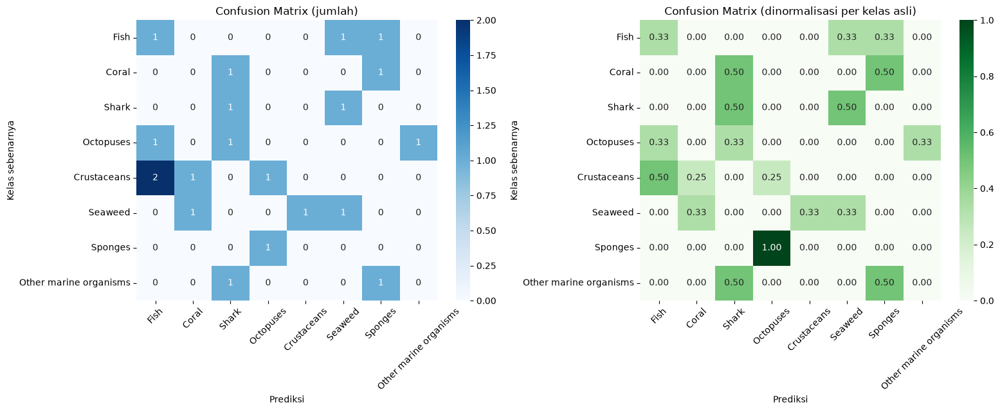

Analisis: Diagonal utama = prediksi benar. Kesalahan terbanyak: 'Crustaceans' diprediksi sebagai 'Fish' (2 gambar), kemungkinan karena kemiripan visual. Kelas dengan recall terendah adalah 'Coral' (0.00).


In [98]:
# 5. Confusion matrix
labels_all = list(range(NUM_CLASSES))
cm = confusion_matrix(y_true, y_pred, labels=labels_all)
np.save(os.path.join(OUT_DIR, "confusion_matrix.npy"), cm)

row_sum = cm.sum(axis=1, keepdims=True)
cm_pct = np.divide(cm, row_sum, out=np.zeros_like(cm, dtype=float), where=row_sum != 0)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title("Confusion Matrix (jumlah)")
sns.heatmap(cm_pct, annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1,
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title("Confusion Matrix (dinormalisasi per kelas asli)")
for a in axes:
    a.set_xlabel("Prediksi"); a.set_ylabel("Kelas sebenarnya"); a.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "6_confusion_matrix.png"), dpi=120, bbox_inches="tight")
plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
if off.max() > 0:
    a_, b_ = np.unravel_index(off.argmax(), off.shape)
    conf_txt = (f"Kesalahan terbanyak: '{class_names[a_]}' diprediksi sebagai '{class_names[b_]}' "
                f"({off[a_, b_]} gambar), kemungkinan karena kemiripan visual.")
else:
    conf_txt = "Tidak ada kesalahan klasifikasi pada data uji."
diag = np.diag(cm_pct)[present]
analysis["confusion_matrix"] = (
    f"Diagonal utama = prediksi benar. {conf_txt} Kelas dengan recall terendah adalah "
    f"'{class_names[present[int(diag.argmin())]]}' ({diag.min():.2f})."
)
print("Analisis:", analysis["confusion_matrix"])

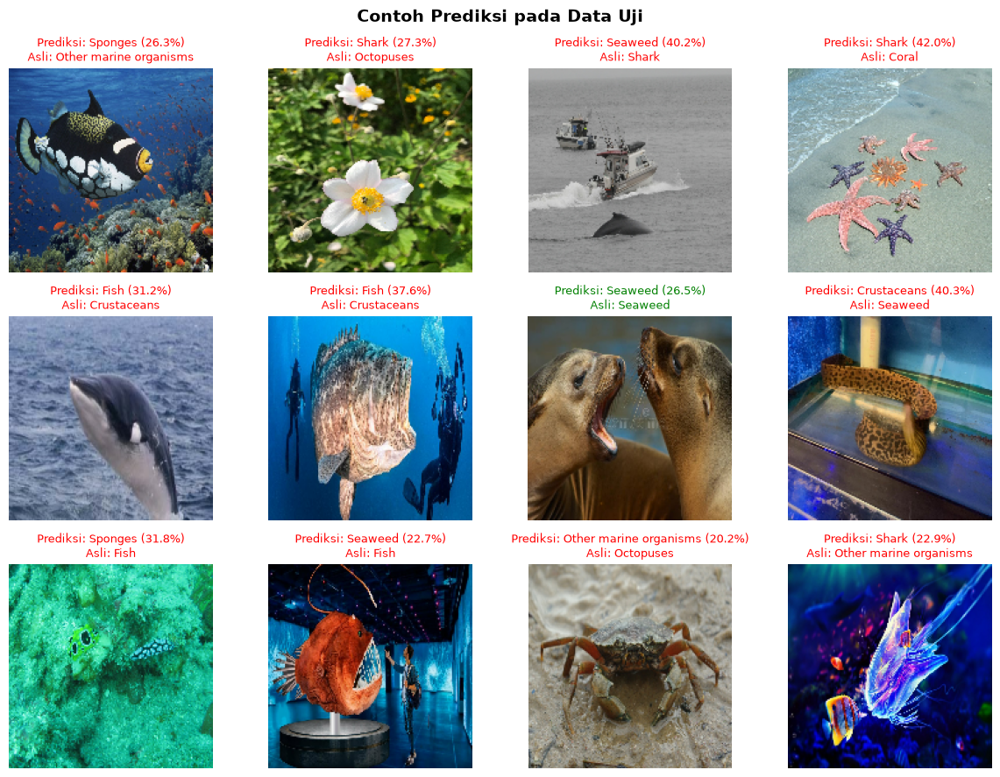

Analisis: Dari 12 gambar uji, 1 diprediksi benar (judul hijau) dan 11 salah (merah). Persentase di judul adalah confidence model; prediksi salah dengan confidence tinggi menandakan kelas yang sangat mirip secara visual.


In [99]:
# 6. Contoh prediksi gambar
n_show = min(12, len(imgs_keep))

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
axes = axes.flatten()

for i, a in enumerate(axes):
    if i >= n_show:
        a.axis("off")
        continue

    img = np.clip(imgs_keep[i] / 255.0, 0, 1)
    pred = int(np.argmax(probs_keep[i]))
    true = int(y_true[i])
    conf = probs_keep[i][pred] * 100

    a.imshow(img)
    a.set_title(
        f"Prediksi: {class_names[pred]} ({conf:.1f}%)\nAsli: {class_names[true]}",
        color="green" if pred == true else "red",
        fontsize=9,
    )
    a.axis("off")

plt.suptitle("Contoh Prediksi pada Data Uji", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "7_sample_predictions.png"), dpi=120, bbox_inches="tight")
plt.show()

n_ok = int(sum(int(np.argmax(probs_keep[i])) == int(y_true[i]) for i in range(n_show)))
analysis["prediksi"] = (
    f"Dari {n_show} gambar uji, {n_ok} diprediksi benar (judul hijau) dan {n_show - n_ok} salah (merah). "
    "Persentase di judul adalah confidence model; prediksi salah dengan confidence tinggi menandakan kelas yang "
    "sangat mirip secara visual."
)
print("Analisis:", analysis["prediksi"])

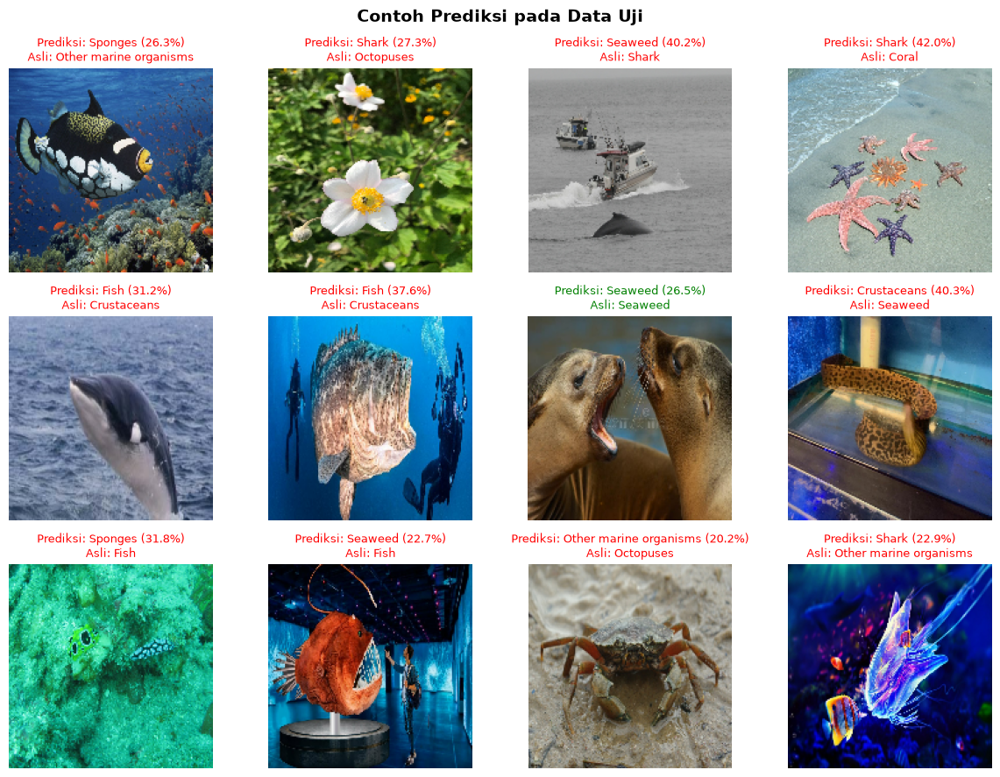

Analisis: Dari 12 gambar uji, 1 diprediksi benar (judul hijau) dan 11 salah (merah). Persentase di judul adalah confidence model; prediksi salah dengan confidence tinggi menandakan kelas yang sangat mirip secara visual.


In [100]:
# 6. Contoh prediksi gambar
n_show = min(12, len(imgs_keep))

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
axes = axes.flatten()

for i, a in enumerate(axes):
    if i >= n_show:
        a.axis("off")
        continue

    img = np.clip(imgs_keep[i] / 255.0, 0, 1)
    pred = int(np.argmax(probs_keep[i]))
    true = int(y_true[i])
    conf = probs_keep[i][pred] * 100

    a.imshow(img)
    a.set_title(
        f"Prediksi: {class_names[pred]} ({conf:.1f}%)\nAsli: {class_names[true]}",
        color="green" if pred == true else "red",
        fontsize=9,
    )
    a.axis("off")

plt.suptitle("Contoh Prediksi pada Data Uji", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "7_sample_predictions.png"), dpi=120, bbox_inches="tight")
plt.show()

n_ok = int(sum(int(np.argmax(probs_keep[i])) == int(y_true[i]) for i in range(n_show)))
analysis["prediksi"] = (
    f"Dari {n_show} gambar uji, {n_ok} diprediksi benar (judul hijau) dan {n_show - n_ok} salah (merah). "
    "Persentase di judul adalah confidence model; prediksi salah dengan confidence tinggi menandakan kelas yang "
    "sangat mirip secara visual."
)
print("Analisis:", analysis["prediksi"])

In [101]:
with open(os.path.join(OUT_DIR, "analysis.json"), "w", encoding="utf-8") as f:
    json.dump(analysis, f, indent=2, ensure_ascii=False)

model.save(os.path.join(OUT_DIR, "final_marine_cnn_model.keras"))

loaded = tf.keras.models.load_model(
    os.path.join(OUT_DIR, "final_marine_cnn_model.keras")
)

print(f'\n Model & semua hasil tersimpan di folder "{OUT_DIR}" dan model berhasil di-load ulang.')

# Jalankan dashboard (dari folder yang berisi app.py dan folder output_oceaniclife):
#   streamlit run app.py


 Model & semua hasil tersimpan di folder "output_oceaniclife" dan model berhasil di-load ulang.
